# LeetCode #354: Russian Doll Envelopes

https://leetcode.com/problems/russian-doll-envelopes/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Sort + LIS with Binary Search ★ | O(n log n) | O(n) |
| DP (LIS) | O(n²) | O(n) |

## Understanding the Methods
### Sort + LIS with Binary Search (Optimal)
Sort envelopes by width ascending, and by height descending when widths are equal. Then find the Longest Increasing Subsequence (LIS) on the heights. The reverse sort on height for same width ensures we do not pick two envelopes with the same width. Binary search (patience sorting) gives O(n log n) LIS.

### DP (LIS)
After sorting, use standard O(n²) DP for LIS. For each envelope, check all previous envelopes for valid nesting. Correct but too slow for large inputs.

## Solutions

### C#

In [ ]:
public class Solution {
    public int MaxEnvelopes(int[][] envelopes) {
        Array.Sort(envelopes, (a, b) => a[0] == b[0] ? b[1] - a[1] : a[0] - b[0]);
        var tails = new List<int>();
        foreach (var e in envelopes) {
            int h = e[1];
            int pos = tails.BinarySearch(h);
            if (pos < 0) pos = ~pos;
            if (pos == tails.Count) tails.Add(h);
            else tails[pos] = h;
        }
        return tails.Count;
    }
}

### Python

In [ ]:
from bisect import bisect_left

class Solution:
    def maxEnvelopes(self, envelopes: list[list[int]]) -> int:
        envelopes.sort(key=lambda x: (x[0], -x[1]))
        tails = []
        for _, h in envelopes:
            pos = bisect_left(tails, h)
            if pos == len(tails):
                tails.append(h)
            else:
                tails[pos] = h
        return len(tails)

### Go

In [ ]:
import "sort"

func maxEnvelopes(envelopes [][]int) int {
    sort.Slice(envelopes, func(i, j int) bool {
        if envelopes[i][0] == envelopes[j][0] {
            return envelopes[i][1] > envelopes[j][1]
        }
        return envelopes[i][0] < envelopes[j][0]
    })

    tails := []int{}
    for _, e := range envelopes {
        h := e[1]
        pos := sort.SearchInts(tails, h)
        if pos == len(tails) {
            tails = append(tails, h)
        } else {
            tails[pos] = h
        }
    }
    return len(tails)
}

### Rust

In [ ]:
impl Solution {
    pub fn max_envelopes(mut envelopes: Vec<Vec<i32>>) -> i32 {
        envelopes.sort_by(|a, b| {
            if a[0] == b[0] { b[1].cmp(&a[1]) }
            else { a[0].cmp(&b[0]) }
        });

        let mut tails: Vec<i32> = Vec::new();
        for e in &envelopes {
            let h = e[1];
            match tails.binary_search(&h) {
                Ok(pos) => tails[pos] = h,
                Err(pos) => {
                    if pos == tails.len() { tails.push(h); }
                    else { tails[pos] = h; }
                }
            }
        }
        tails.len() as i32
    }
}

## Example Scenarios

### 1. Common Case — Standard Nesting Chain
**Input:** `envelopes = [[5,4],[6,4],[6,7],[2,3]]`
Sort by width ascending → `[[2,3],[5,4],[6,7],[6,4]]`, then run LIS (patience sorting) on the heights `[3,4,7,4]`. The increasing subsequence `3 → 4 → 7` nests three envelopes.
**Output:** `3`

### 2. Slightly Complex — Equal Widths, Height Descending Tie-Break
**Input:** `envelopes = [[2,3],[5,4],[5,2],[6,5]]`
Two envelopes share width 5. Sorting height **descending** for equal widths → `[[2,3],[5,4],[5,2],[6,5]]` guarantees the LIS can never pick both width-5 envelopes (heights `4` then `2` are not increasing). LIS on `[3,4,2,5]` = `3 → 4 → 5`.
**Output:** `3`

### 3. Edge Case: Time Factor — Fully Nestable Chain
**Input:** `envelopes = [[1,1],[2,2],[3,3],[4,4]]`
Every envelope fits inside the next. `bisect_left` always returns the end, so `tails` **appends** at each step — the binary-search LIS still runs in $O(n \log n)$ even when the answer equals $n$.
**Output:** `4`

### 4. Edge Case: Space Factor — Single Envelope
**Input:** `envelopes = [[1,1]]`
One envelope: `tails` grows to length 1 and stops. Both the sort and the `tails` array are $O(n) = O(1)$ here — the minimal-space case.
**Output:** `1`

### 5. Almost-Impossible but Plausible — All Identical
**Input:** `envelopes = [[3,3],[3,3],[3,3]]`
All envelopes are the same size, so none can nest. Height-descending order makes the heights non-increasing, and `tails` never grows past length 1.
**Output:** `1`


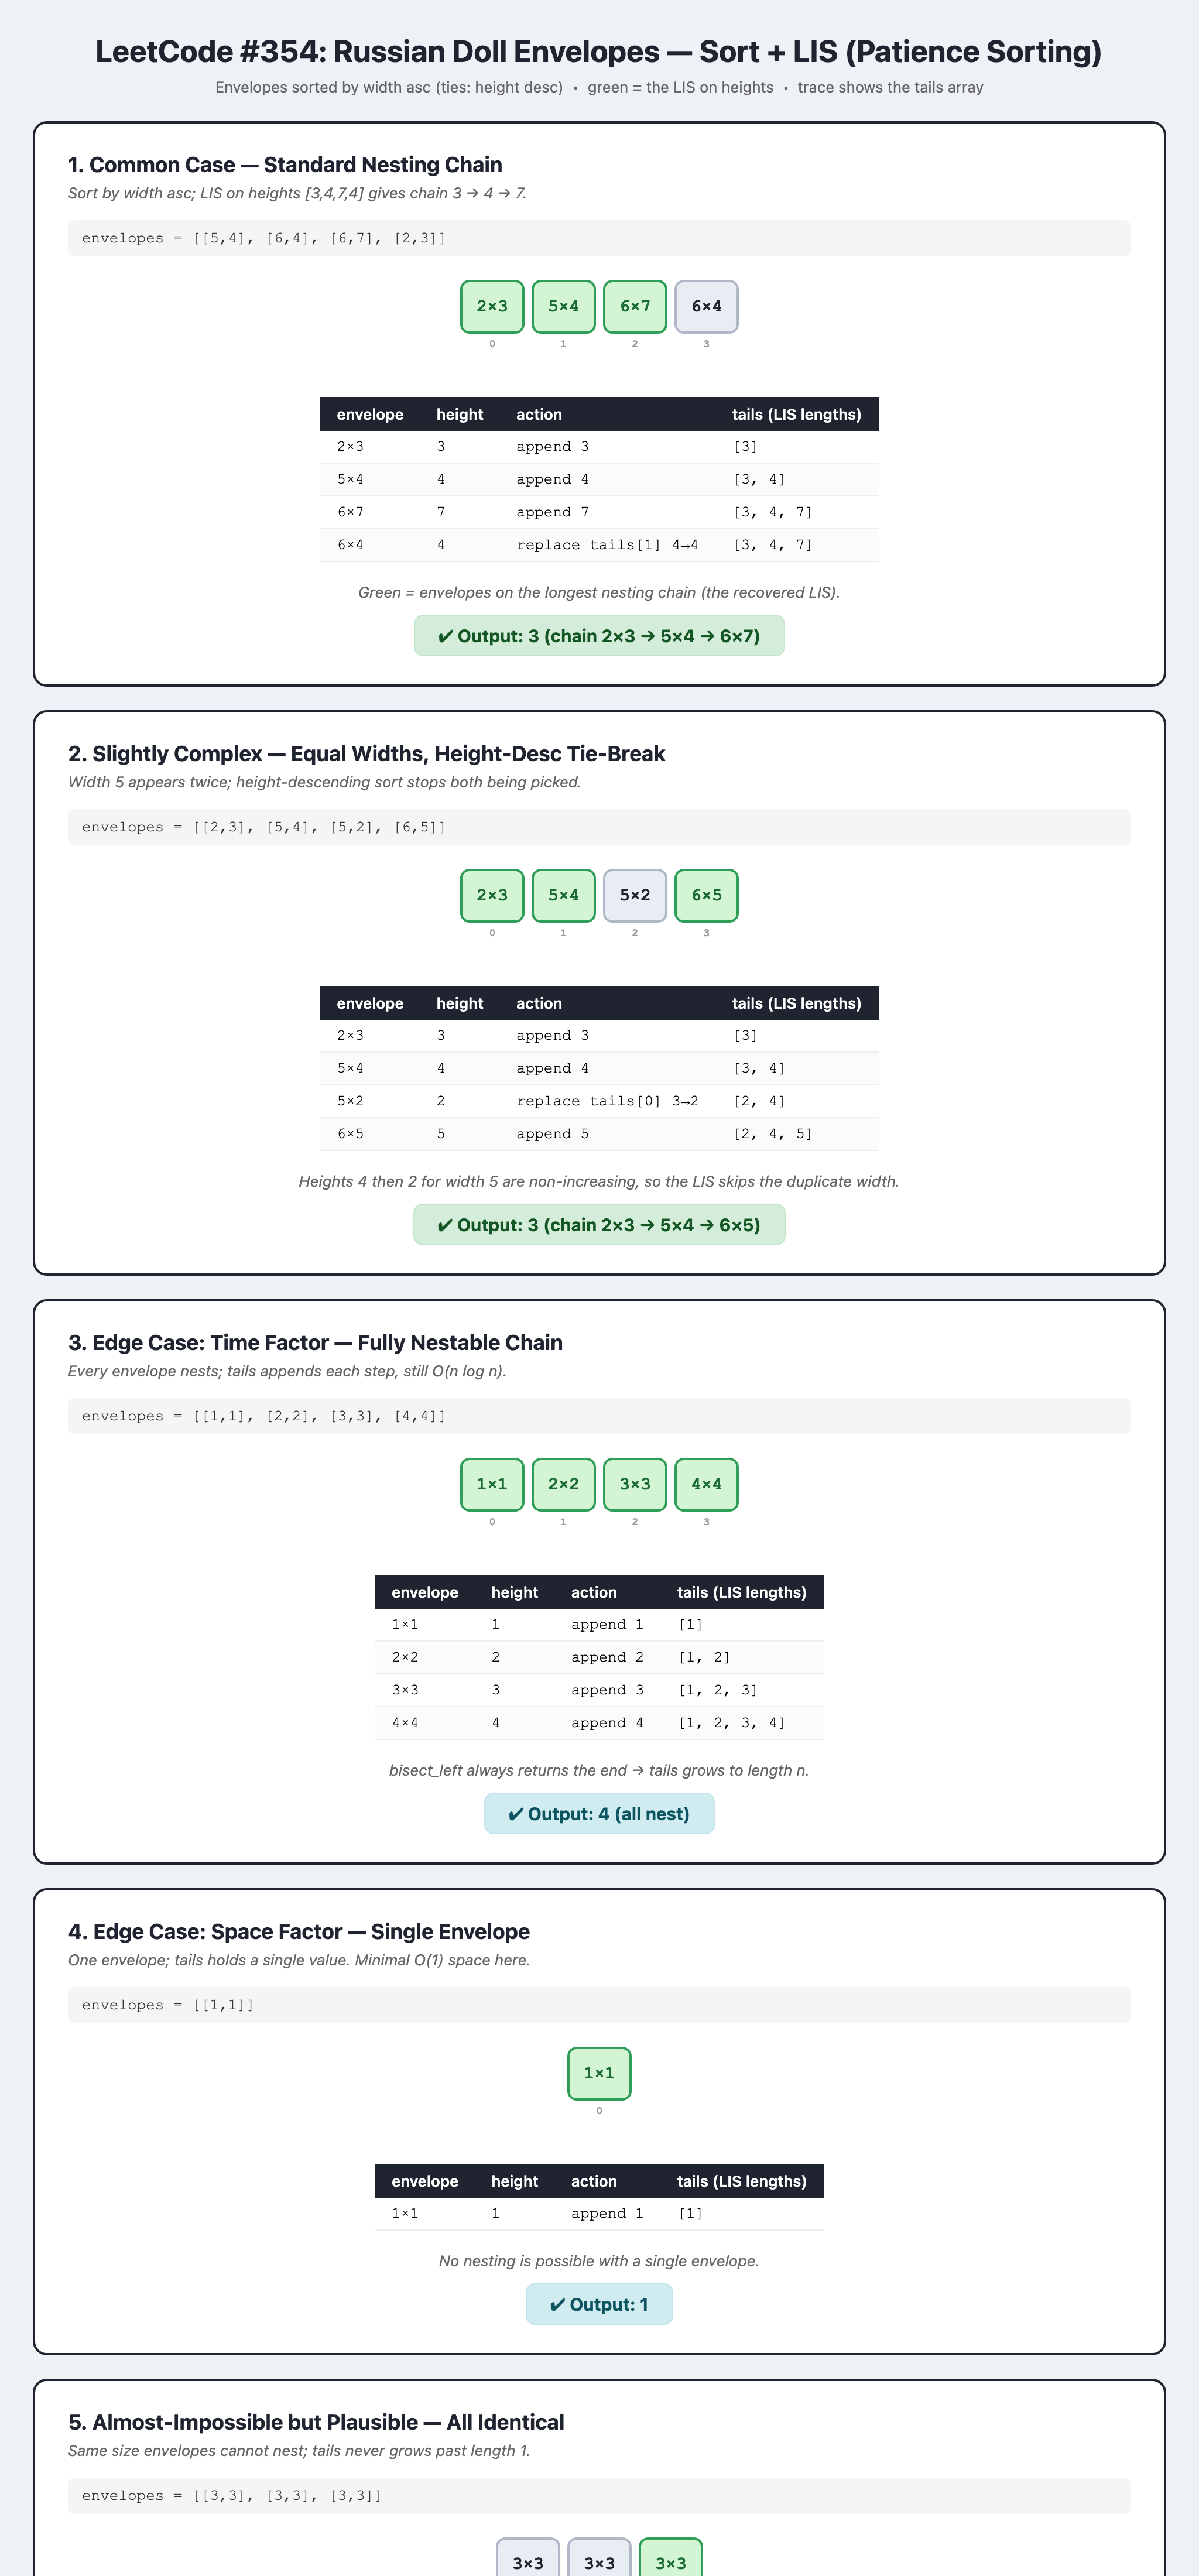